# Lab 5
- **Student Name**: Daniel Alejandro Castillo Martin
- **Student ID**: N10019284
- **Course:** Advanced Deep Learning - AIGC-5500-0NA
- **Professor**: Hossein Pourmodheji
---

This lab implements scaled dot-product and multi-head attention from scratch and verifies them against PyTorch. Experiments compare attention with an LSTM on delayed recall, evaluate positional encodings on an order task, and examine normalization and computational cost. Results across three seeds are used to assess each approach and its limitations.

## 1. Imports and Setup

### 1.1 Libraries

In [15]:
# Import required libraries
import math
import platform
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

# Lab starter module
from scripts.lab05_starter import train_recall, train_order

### 1.2 Constants

In [16]:
# Save experiment tables and figures.
OUTPUT_DIR = Path('output')
OUTPUT_DIR.mkdir(exist_ok=True)

# Use the three seeds required by the lab.
SEEDS = (0, 1, 2)

### 1.3 Reproducibility and Options

In [17]:
# Set the seed for reproducibility
torch.manual_seed(0)

# Set the display options for pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 4)

In [18]:
# Validate the environment configuration
print(f'Python: {platform.python_version()}')
print(f'PyTorch: {torch.__version__}')
print(f'Interpreter: {sys.executable}')
print(f'Working directory: {Path.cwd()}')
print(f'CPU threads: {torch.get_num_threads()}')
print(f'Seeds: {SEEDS}')

Python: 3.14.6
PyTorch: 2.14.1+cpu
Interpreter: c:\Users\dancm\Documents\humber-aigc-postgraduate\aigc-5500-advanced-deep-learning\labs\lab-05\env\Scripts\python.exe
Working directory: c:\Users\dancm\Documents\humber-aigc-postgraduate\aigc-5500-advanced-deep-learning\labs\lab-05
CPU threads: 12
Seeds: (0, 1, 2)


## 2. Attention from Scratch and Verification

### 2.1 Scaled Dot-Product Attention

Attention compares queries with keys, scales the scores, and applies softmax over the key positions. The resulting weights produce a weighted sum of values.

A boolean mask uses True for allowed positions and False for blocked positions.

In [20]:
def scaled_dot_product_attention(q, k, v, mask=None):
    # Compare each query with every key and scale the scores.
    scores = (q @ k.transpose(-2, -1)) / math.sqrt(q.shape[-1])

    if mask is not None:
        assert mask.dtype == torch.bool, 'The mask must be boolean.'
        assert mask.any(dim = -1).all(), 'Each query needs an allowed key.'

        # Block positions BEFORE applying softmax.
        scores = scores.masked_fill(~mask, float('-inf'))

    # Normalize over keys: each query gets a distribution over key positions.
    weights = torch.softmax(scores, dim = -1)

    # Verify the probability and masking requirements.
    row_sums = weights.sum(dim = -1)
    assert torch.allclose(
        row_sums,
        torch.ones_like(row_sums),
        atol = 0.000001,
        rtol = 0.00001,
    ), 'Attention weight rows must sum to 1.'

    if mask is not None:
        blocked = (~mask).expand_as(weights)
        assert torch.all(
            weights.masked_select(blocked) == 0
        ), 'Masked positions must have exactly zero weight.'

    output = weights @ v
    return output, weights

### 2.2 Verification Against PyTorch

The custom attention function is compared with PyTorch using identical random inputs, with and without a causal mask. The causal mask allows each query to attend only to its own position and earlier positions.

In [25]:
attention_checks = []

for seed in SEEDS:
    generator = torch.Generator().manual_seed(seed)

    # Shape: (batch, sequence length, feature dimension).
    q = torch.randn(2, 5, 8, generator=generator)
    k = torch.randn(2, 5, 8, generator=generator)
    v = torch.randn(2, 5, 6, generator=generator)

    # True means attention is allowed.
    causal_mask = torch.ones(5, 5, dtype=torch.bool).tril()

    for name, mask in [('Unmasked', None), ('Causal', causal_mask),]:
        custom_output, weights = scaled_dot_product_attention(q, k, v, mask)

        reference_output = F.scaled_dot_product_attention(q, k, v, attn_mask = mask, dropout_p = 0.0)

        torch.testing.assert_close(custom_output, reference_output, atol = 0.000001, rtol=0.00001)

        attention_checks.append({
            'seed': seed,
            'case': name,
            'max_absolute_error': (custom_output - reference_output).abs().max().item(),
            'passed': True
            })

attention_checks_df = pd.DataFrame(attention_checks)

attention_checks_df.to_csv(OUTPUT_DIR / 'attention_function_checks.csv', index = False)

print('All attention function checks passed.')

All attention function checks passed.


In [26]:
# Show the attention checks dataframe
attention_checks_df

,seed,case,max_absolute_error,passed
0,0,Unmasked,1.7881e-07,True
1,0,Causal,1.1921e-07,True
2,1,Unmasked,1.7881e-07,True
3,1,Causal,3.5763e-07,True
4,2,Unmasked,1.1921e-07,True
5,2,Causal,1.1921e-07,True


### 2.3 Multi-Head Attention

Multi-head attention projects inputs into queries, keys, and values, splits their features across heads, and applies attention independently within each head. The head outputs are concatenated and passed through an output projection.

An optional context supplies keys and values for cross-attention.

In [23]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()

        assert n_heads > 0, 'n_heads must be positive.'
        assert d_model % n_heads == 0, 'd_model must be divisible by n_heads.'

        self.d_model = d_model
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads

        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)

    def split_heads(self, x):
        batch_size, length, _ = x.shape

        # (B, T, D) -> (B, T, H, Dh) -> (B, H, T, Dh)
        return x.reshape(batch_size, length, self.n_heads, self.head_dim).transpose(1, 2)

    def forward(self, x, context = None, mask = None):
        # Self-attention uses x for queries, keys, and values.
        context = x if context is None else context

        q = self.split_heads(self.q_proj(x))
        k = self.split_heads(self.k_proj(context))
        v = self.split_heads(self.v_proj(context))

        head_outputs, _ = scaled_dot_product_attention(q, k, v, mask)

        batch_size, _, query_length, _ = head_outputs.shape

        # (B, H, Tq, Dh) -> (B, Tq, H, Dh) -> (B, Tq, D)
        combined = head_outputs.transpose(1, 2).reshape(batch_size, query_length, self.d_model)

        return self.out_proj(combined)

### 2.4 Multi-Head Attention Verification

The custom module is compared with PyTorch's MultiheadAttention after copying the same projection weights and biases. Checks cover self-attention, causal self-attention, and cross-attention with different query and context lengths.

In [28]:
mha_checks = []

for seed in SEEDS:
    torch.manual_seed(seed)

    custom_mha = MultiHeadAttention(d_model = 32, n_heads = 4)
    reference_mha = nn.MultiheadAttention(embed_dim = 32, num_heads = 4, dropout = 0.0, batch_first = True)

    # PyTorch stores the Q, K, and V projections in one stacked tensor.
    with torch.no_grad():
        reference_mha.in_proj_weight.copy_(torch.cat([custom_mha.q_proj.weight, custom_mha.k_proj.weight, custom_mha.v_proj.weight,], dim = 0))
        reference_mha.in_proj_bias.copy_(torch.cat([custom_mha.q_proj.bias, custom_mha.k_proj.bias, custom_mha.v_proj.bias, ], dim = 0))
        reference_mha.out_proj.weight.copy_(custom_mha.out_proj.weight)
        reference_mha.out_proj.bias.copy_(custom_mha.out_proj.bias)

    custom_mha.eval()
    reference_mha.eval()

    generator = torch.Generator().manual_seed(seed + 1000)
    x = torch.randn(2, 5, 32, generator = generator)
    context = torch.randn(2, 7, 32, generator = generator)
    causal_mask = torch.ones(5, 5, dtype = torch.bool).tril()

    cases = [('Self-attention', None, None), ('Causal self-attention', None, causal_mask), ('Cross-attention', context, None)]

    with torch.no_grad():
        for name, ctx, mask in cases:
            custom_output = custom_mha(x, context = ctx, mask = mask)

            kv = x if ctx is None else ctx

            # nn.MultiheadAttention uses True for BLOCKED positions.
            blocked_mask = None if mask is None else ~mask

            reference_output, _ = reference_mha(x, kv, kv, attn_mask = blocked_mask, need_weights = False)

            torch.testing.assert_close(custom_output, reference_output, atol = 0.000001, rtol = 0.00001)

            mha_checks.append({
                'seed': seed,
                'case': name,
                'query_length': x.shape[1],
                'key_length': kv.shape[1],
                'max_absolute_error': (custom_output - reference_output).abs().max().item(),
                'passed': True
                })

mha_checks_df = pd.DataFrame(mha_checks)

mha_checks_df.to_csv(OUTPUT_DIR / 'multihead_attention_checks.csv', index = False,)

print('All multi-head attention checks passed.')

All multi-head attention checks passed.


In [29]:
# Show the multi-head attention checks dataframe
mha_checks_df

,seed,case,query_length,key_length,max_absolute_error,passed
0,0,Self-attention,5,5,5.9605e-08,True
1,0,Causal self-attention,5,5,8.9407e-08,True
2,0,Cross-attention,5,7,5.9605e-08,True
3,1,Self-attention,5,5,5.9605e-08,True
4,1,Causal self-attention,5,5,7.4506e-08,True
5,1,Cross-attention,5,7,1.1921e-07,True
6,2,Self-attention,5,5,7.6368e-08,True
7,2,Causal self-attention,5,5,7.4506e-08,True
8,2,Cross-attention,5,7,5.9605e-08,True


### 2.5 Parameter Counts

Parameter counts are measured at a fixed model width of 32 using 1, 2, 4, and 8 heads.

In [30]:
parameter_counts = []

for n_heads in (1, 2, 4, 8):
    model = MultiHeadAttention(d_model = 32, n_heads = n_heads)

    parameter_counts.append({
        'd_model': 32,
        'n_heads': n_heads,
        'head_dim': model.head_dim,
        'parameters': sum(p.numel() for p in model.parameters())
        })

parameter_counts_df = pd.DataFrame(parameter_counts)

parameter_counts_df.to_csv(OUTPUT_DIR / 'attention_parameter_counts.csv', index = False)

In [31]:
# Show the parameter counts dataframe
parameter_counts_df

,d_model,n_heads,head_dim,parameters
0,32,1,32,4224
1,32,2,16,4224
2,32,4,8,4224
3,32,8,4,4224


At a fixed model width, increasing the number of heads changes how features are partitioned but leaves the four projection layers unchanged, so the parameter count remains 4,224.

### 2.6 Permutation Equivariance

Without positional encodings or a mask, shuffling input positions should shuffle the output positions in the same way. This property is checked using the same layer and parameters for both inputs.

In [32]:
permutation_checks = []

for seed in SEEDS:
    torch.manual_seed(seed)

    model = MultiHeadAttention(d_model = 32, n_heads = 4)
    model.eval()

    generator = torch.Generator().manual_seed(seed + 2000)
    x = torch.randn(2, 7, 32, generator = generator)
    permutation = torch.randperm(7, generator = generator)

    with torch.no_grad():
        original_output = model(x)
        shuffled_output = model(x[:, permutation, :])

        expected_output = original_output[:, permutation, :]

        torch.testing.assert_close(shuffled_output, expected_output, atol = 0.000001, rtol = 0.00001)

    permutation_checks.append({
        'seed': seed,
        'max_absolute_error': (shuffled_output - expected_output).abs().max().item(),
        'passed': True
        })

permutation_checks_df = pd.DataFrame(permutation_checks)

permutation_checks_df.to_csv(OUTPUT_DIR / 'attention_permutation_checks.csv', index = False)

print('All permutation equivariance checks passed.')

All permutation equivariance checks passed.


In [33]:
# Show the permutation checks dataframe
permutation_checks_df

,seed,max_absolute_error,passed
0,0,1.1921e-07,True
1,1,8.9407e-08,True
2,2,1.1921e-07,True


## 3. Delayed Recall: Attention Against an LSTM

The attention readout and an LSTM with forget bias 3 are trained at sequence lengths 30, 100, and 400 using seeds 0, 1, and 2. Both use the starter's default training settings and identical data for each matching length and seed.

Chance accuracy is 0.25. The attention model also reports its mean weight on step 0, where the class information is stored.

### 3.1 Training and Results

In [ ]:
recall_results = []

for seq_len in (30, 100, 400):
    for seed in SEEDS:
        for kind in ('attention', 'lstm'):
            print(f'Running {kind}: length = {seq_len}, seed = {seed}', flush = True)

            start = perf_counter()

            accuracy, weight0 = train_recall(kind, seq_len = seq_len, seed = seed, attention_fn=scaled_dot_product_attention)

            recall_results.append({
                'model': kind,
                'seq_len': seq_len,
                'seed': seed,
                'accuracy': accuracy,
                'chance': 0.25,
                'above_chance': accuracy - 0.25,
                'weight_on_step_0': weight0,
                'elapsed_seconds': perf_counter() - start,
                })

            # Save progress after every completed run.
            pd.DataFrame(recall_results).to_csv(OUTPUT_DIR / 'recall_results.csv', index = False)
            weight_text = ('N/A' if weight0 is None else f'{weight0:.4f}')
            print(f'  Accuracy={accuracy:.3f}, 'f'weight on step 0 = {weight_text}', flush = True)

recall_results_df = pd.DataFrame(recall_results)

Running attention: length = 30, seed = 0
  Accuracy=1.000, weight on step 0 = 0.7301
Running lstm: length = 30, seed = 0
  Accuracy=1.000, weight on step 0 = N/A
Running attention: length = 30, seed = 1
  Accuracy=1.000, weight on step 0 = 0.7424
Running lstm: length = 30, seed = 1
  Accuracy=1.000, weight on step 0 = N/A
Running attention: length = 30, seed = 2
  Accuracy=1.000, weight on step 0 = 0.6742
Running lstm: length = 30, seed = 2
  Accuracy=1.000, weight on step 0 = N/A
Running attention: length = 100, seed = 0
  Accuracy=1.000, weight on step 0 = 0.7382
Running lstm: length = 100, seed = 0
  Accuracy=0.252, weight on step 0 = N/A
Running attention: length = 100, seed = 1
  Accuracy=1.000, weight on step 0 = 0.7459
Running lstm: length = 100, seed = 1
  Accuracy=1.000, weight on step 0 = N/A
Running attention: length = 100, seed = 2
  Accuracy=1.000, weight on step 0 = 0.6577
Running lstm: length = 100, seed = 2
  Accuracy=1.000, weight on step 0 = N/A
Running attention: len

In [35]:
# Show the recall results dataframe
recall_results_df

,model,seq_len,seed,accuracy,chance,above_chance,weight_on_step_0,elapsed_seconds
0,attention,30,0,1.000,0.25,0.750,0.7301,5.4040
1,lstm,30,0,1.000,0.25,0.750,NaN,7.4136
2,attention,30,1,1.000,0.25,0.750,0.7424,2.2936
3,lstm,30,1,1.000,0.25,0.750,NaN,4.7396
4,attention,30,2,1.000,0.25,0.750,0.6742,1.8654
5,lstm,30,2,1.000,0.25,0.750,NaN,5.1362
6,attention,100,0,1.000,0.25,0.750,0.7382,3.6694
7,lstm,100,0,0.252,0.25,0.002,NaN,15.8200
8,attention,100,1,1.000,0.25,0.750,0.7459,3.9654
9,lstm,100,1,1.000,0.25,0.750,NaN,13.3818


### 3.2 Recall Results Visualization

Accuracy and attention weight on step 0 are plotted for every seed. The dashed accuracy line indicates chance performance (0.25).

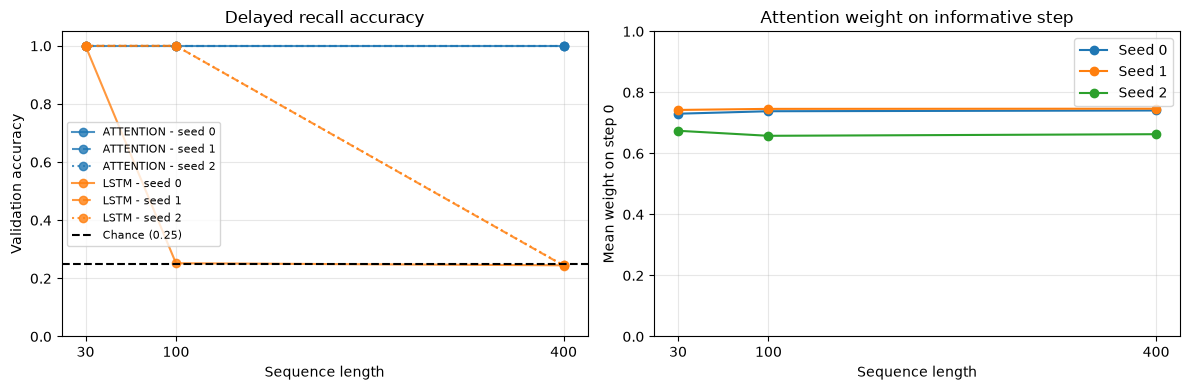

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

colors = {'attention': 'tab:blue', 'lstm': 'tab:orange'}

for kind in ('attention', 'lstm'):
    for seed in SEEDS:
        subset = recall_results_df[(recall_results_df['model'] == kind) & (recall_results_df['seed'] == seed)].sort_values('seq_len')

        axes[0].plot(
            subset['seq_len'],
            subset['accuracy'],
            marker = 'o',
            linestyle = ('-', '--', ':')[seed],
            color = colors[kind],
            label = f'{kind.upper()} - seed {seed}',
            alpha = 0.8
            )

axes[0].axhline(0.25, color = 'black', linestyle = '--', label = 'Chance (0.25)')
axes[0].set_title('Delayed recall accuracy')
axes[0].set_xlabel('Sequence length')
axes[0].set_ylabel('Validation accuracy')
axes[0].set_ylim(0, 1.05)
axes[0].set_xticks([30, 100, 400])
axes[0].legend(fontsize = 8)

for seed in SEEDS:
    subset = recall_results_df[(recall_results_df['model'] == 'attention') & (recall_results_df['seed'] == seed)].sort_values('seq_len')

    axes[1].plot(
        subset['seq_len'],
        subset['weight_on_step_0'],
        marker = 'o',
        label = f'Seed {seed}'
        )

axes[1].set_title('Attention weight on informative step')
axes[1].set_xlabel('Sequence length')
axes[1].set_ylabel('Mean weight on step 0')
axes[1].set_ylim(0, 1)
axes[1].set_xticks([30, 100, 400])
axes[1].legend()

for ax in axes:
    ax.grid(alpha = 0.3)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'recall_results.png', dpi = 200, bbox_inches = 'tight')
plt.show()

### 3.3 Interpretation

- Attention achieved 1.000 accuracy at every tested length and seed, exceeding chance (0.25) by 0.750. Its mean attention weight on step 0 ranged from approximately 0.658 to 0.747, showing that the readout concentrated on the informative input even at length 400.

- The LSTM achieved 1.000 accuracy for every seed at length 30. At length 100, seeds 1 and 2 achieved 1.000, while seed 0 reached only 0.252. At length 400, all seeds remained near chance, with accuracies of 0.244-0.245.

- The attention readout directly accesses the informative step through a weighted sum. The LSTM must preserve that information through successive recurrent updates before classification at the final step. These results are consistent with greater difficulty retaining information over longer sequences under the tested training budget.

## 4. Positional Encodings on the Order Task

Each sequence contains markers 1 and 2 once, plus filler tokens. The label indicates which marker appears first, so chance accuracy is 0.50.

The classifier uses the custom multi-head attention module. Each positional configuration is trained at length 16 and evaluated at lengths 16 and 32, using seeds 0, 1, and 2.

### 4.1 Fixed-Length Training

In [40]:
position_results = []

for pos in ('none', 'learned', 'sinusoidal'):
    for seed in SEEDS:
        print(f'Running positions={pos}, seed={seed}', flush = True)

        start = perf_counter()
        accuracies = train_order(pos, seed = seed, train_len = 16, test_lens = (16, 32), attention_cls = MultiHeadAttention)
        elapsed = perf_counter() - start

        for test_len, accuracy in zip((16, 32), accuracies):
            position_results.append({
                'positions': pos,
                'training': 'fixed_16',
                'seed': seed,
                'test_len': test_len,
                'accuracy': accuracy,
                'chance': 0.50,
                'above_chance': accuracy - 0.50,
                'training_seconds': elapsed
                })

        pd.DataFrame(position_results).to_csv(OUTPUT_DIR / 'position_fixed_results.csv', index = False)

        print(f'  Length 16: {accuracies[0]:.3f}, 'f'length 32: {accuracies[1]:.3f}', flush = True)

position_results_df = pd.DataFrame(position_results)


Running positions=none, seed=0
  Length 16: 0.552, length 32: 0.503
Running positions=none, seed=1
  Length 16: 0.523, length 32: 0.484
Running positions=none, seed=2
  Length 16: 0.447, length 32: 0.498
Running positions=learned, seed=0
  Length 16: 1.000, length 32: 0.626
Running positions=learned, seed=1
  Length 16: 1.000, length 32: 0.606
Running positions=learned, seed=2
  Length 16: 1.000, length 32: 0.622
Running positions=sinusoidal, seed=0
  Length 16: 1.000, length 32: 0.624
Running positions=sinusoidal, seed=1
  Length 16: 1.000, length 32: 0.665
Running positions=sinusoidal, seed=2
  Length 16: 1.000, length 32: 0.748


In [ ]:
# Show fixed-length position results dataframe
position_results_df

,positions,training,seed,test_len,accuracy,chance,above_chance,training_seconds
0,none,fixed_16,0,16,0.552,0.5,0.052,14.0726
1,none,fixed_16,0,32,0.503,0.5,0.003,14.0726
2,none,fixed_16,1,16,0.523,0.5,0.023,13.3939
3,none,fixed_16,1,32,0.484,0.5,-0.016,13.3939
4,none,fixed_16,2,16,0.447,0.5,-0.053,13.4092
5,none,fixed_16,2,32,0.498,0.5,-0.002,13.4092
6,learned,fixed_16,0,16,1.000,0.5,0.500,13.7242
7,learned,fixed_16,0,32,0.626,0.5,0.126,13.7242
8,learned,fixed_16,1,16,1.000,0.5,0.500,14.2065
9,learned,fixed_16,1,32,0.606,0.5,0.106,14.2065


### 4.2 Fixed-Length Results Interpretation

Without positional encodings, accuracy remained around chance (0.50). Self-attention is permutation equivariant, and mean pooling removes position order, preventing this classifier from reliably distinguishing which marker comes first.

Learned and sinusoidal encodings both achieved 1.000 accuracy at length 16.
At length 32, learned encodings reached 0.606–0.626 and sinusoidal encodings reached 0.624–0.748. Providing position information enabled learning at the training length, but did not guarantee generalization to longer sequences.

### 4.3 Mixed-Length Training

Learned and sinusoidal positional encodings are trained using lengths randomly drawn from 8, 16, and 24. Evaluation uses lengths 16, 32, and 48 for each of the three seeds. Other training settings remain unchanged.

In [42]:
mixed_position_results = []

for pos in ('learned', 'sinusoidal'):
    for seed in SEEDS:
        print(f'Running mixed lengths: {pos}, seed={seed}', flush=True)

        accuracies = train_order(pos, seed = seed, mixed_lens = (8, 16, 24), test_lens = (16, 32, 48), attention_cls = MultiHeadAttention)

        for test_len, accuracy in zip((16, 32, 48), accuracies):
            mixed_position_results.append({
                'positions': pos,
                'training': 'mixed_8_16_24',
                'seed': seed,
                'test_len': test_len,
                'accuracy': accuracy,
                'chance': 0.50,
                'above_chance': accuracy - 0.50
                })

        pd.DataFrame(mixed_position_results).to_csv(OUTPUT_DIR / 'position_mixed_results.csv', index = False)

        print('  ' + ', '.join(f'Length {length}: {accuracy:.3f}' for length, accuracy in zip((16, 32, 48), accuracies)), flush = True)

mixed_position_results_df = pd.DataFrame(mixed_position_results)

Running mixed lengths: learned, seed=0
  Length 16: 0.994, Length 32: 0.716, Length 48: 0.548
Running mixed lengths: learned, seed=1
  Length 16: 1.000, Length 32: 0.715, Length 48: 0.547
Running mixed lengths: learned, seed=2
  Length 16: 1.000, Length 32: 0.718, Length 48: 0.532
Running mixed lengths: sinusoidal, seed=0
  Length 16: 1.000, Length 32: 0.894, Length 48: 0.622
Running mixed lengths: sinusoidal, seed=1
  Length 16: 1.000, Length 32: 0.912, Length 48: 0.587
Running mixed lengths: sinusoidal, seed=2
  Length 16: 1.000, Length 32: 0.930, Length 48: 0.762


In [43]:
# Show mixed position results dataframe
mixed_position_results_df

,positions,training,seed,test_len,accuracy,chance,above_chance
0,learned,mixed_8_16_24,0,16,0.994,0.5,0.494
1,learned,mixed_8_16_24,0,32,0.716,0.5,0.216
2,learned,mixed_8_16_24,0,48,0.548,0.5,0.048
3,learned,mixed_8_16_24,1,16,1.000,0.5,0.500
4,learned,mixed_8_16_24,1,32,0.715,0.5,0.215
5,learned,mixed_8_16_24,1,48,0.547,0.5,0.047
6,learned,mixed_8_16_24,2,16,1.000,0.5,0.500
7,learned,mixed_8_16_24,2,32,0.718,0.5,0.218
8,learned,mixed_8_16_24,2,48,0.532,0.5,0.032
9,sinusoidal,mixed_8_16_24,0,16,1.000,0.5,0.500


### 4.4 Comparison with the Prediction

The prediction was supported at length 32 for every seed. Mixed-length training increased learned-position accuracy from 0.606–0.626 to 0.715-0.718, and sinusoidal-position accuracy from 0.624-0.748 to 0.894-0.930. Both exceeded chance accuracy (0.50).

Learned positions benefited from training additional position vectors, but positions beyond index 23 remained untrained. Sinusoidal positions provided consistent vectors across lengths, and exposure to different training lengths improved generalization in these runs.

At length 48, learned-position accuracy fell to 0.532–0.548, near chance, while sinusoidal-position accuracy ranged from 0.587 to 0.762. Thus, mixed-length training improved length-32 performance but did not produce reliable extrapolation to arbitrary lengths.

These results use three seeds and a fixed update budget. Mixed-length training also changes the number of tokens processed and the generated training examples, so the comparison does not isolate positional coverage as the sole cause of improvement.

## 5. Normalization and Computational Cost

### 5.1 Deep Transformer Stacks

Twelve-block classifiers are trained for 400 updates at learning rate 0.003 with sinusoidal positions and the custom multi-head attention. Three settings are compared across seeds 0, 1, and 2: post-norm without warmup, post-norm with 100-update warmup, and pre-norm without warmup. Training and evaluation use length 16. Chance accuracy is 0.50.

In [44]:
stack_results = []

stack_configs = [('Post-norm, no warmup', 'post', 0), ('Post-norm, 100-update warmup', 'post', 100), ('Pre-norm, no warmup', 'pre', 0)]

for name, norm, warmup in stack_configs:
    for seed in SEEDS:
        print(f'Running {name}, seed={seed}', flush=True)

        start = perf_counter()

        accuracies = train_order(
            'sinusoidal',
            seed = seed,
            depth = 12,
            norm = norm,
            warmup = warmup,
            steps = 400,
            lr = 0.003,
            train_len = 16,
            test_lens = (16,),
            attention_cls = MultiHeadAttention
            )

        stack_results.append({
            'configuration': name,
            'norm': norm,
            'warmup': warmup,
            'seed': seed,
            'depth': 12,
            'updates': 400,
            'learning_rate': 3e-3,
            'accuracy': accuracies[0],
            'chance': 0.50,
            'above_chance': accuracies[0] - 0.50,
            'elapsed_seconds': perf_counter() - start
        })

        pd.DataFrame(stack_results).to_csv(OUTPUT_DIR / 'normalization_results.csv', index = False)

        print(f'  Accuracy: {accuracies[0]:.3f}', flush = True)

stack_results_df = pd.DataFrame(stack_results)

Running Post-norm, no warmup, seed=0
  Accuracy: 0.552
Running Post-norm, no warmup, seed=1
  Accuracy: 0.552
Running Post-norm, no warmup, seed=2
  Accuracy: 0.448
Running Post-norm, 100-update warmup, seed=0
  Accuracy: 1.000
Running Post-norm, 100-update warmup, seed=1
  Accuracy: 1.000
Running Post-norm, 100-update warmup, seed=2
  Accuracy: 1.000
Running Pre-norm, no warmup, seed=0
  Accuracy: 1.000
Running Pre-norm, no warmup, seed=1
  Accuracy: 1.000
Running Pre-norm, no warmup, seed=2
  Accuracy: 1.000


In [46]:
# Show the normalization results dataframe
stack_results_df

,configuration,norm,warmup,seed,depth,updates,learning_rate,accuracy,chance,above_chance,elapsed_seconds
0,"Post-norm, no warmup",post,0,0,12,400,0.003,0.552,0.5,0.052,38.6044
1,"Post-norm, no warmup",post,0,1,12,400,0.003,0.552,0.5,0.052,33.0380
2,"Post-norm, no warmup",post,0,2,12,400,0.003,0.448,0.5,-0.052,38.8287
3,"Post-norm, 100-update warmup",post,100,0,12,400,0.003,1.000,0.5,0.500,35.1771
4,"Post-norm, 100-update warmup",post,100,1,12,400,0.003,1.000,0.5,0.500,33.9840
5,"Post-norm, 100-update warmup",post,100,2,12,400,0.003,1.000,0.5,0.500,33.8252
6,"Pre-norm, no warmup",pre,0,0,12,400,0.003,1.000,0.5,0.500,33.6993
7,"Pre-norm, no warmup",pre,0,1,12,400,0.003,1.000,0.5,0.500,41.9811
8,"Pre-norm, no warmup",pre,0,2,12,400,0.003,1.000,0.5,0.500,39.5854


### 5.2 Normalization Results Interpretation

Post-norm without warmup remained near chance (0.50), with accuracies of 0.552, 0.552, and 0.448. Post-norm with 100-update warmup and pre-norm without warmup both achieved 1.000 accuracy for all three seeds.

Under this task and training budget, warmup enabled successful learning for the post-norm stack, while the pre-norm stack learned without warmup. These results do not establish that post-norm always requires warmup. Only one depth, learning rate, task, and update budget were tested, and final accuracy alone does not identify the precise optimization failure.

### 5.3 Forward and Backward Timing

One LSTM layer and one custom attention layer are timed on CPU at matching width 32, batch size 32, and sequence lengths 100, 200, 400, and 800. Each measurement includes a forward pass and backward pass, excluding input generation and gradient clearing. After one untimed warmup pass, the best of three repeats is reported for each seed.

The attention implementation includes its probability assertions. These timings compare the actual implementations, rather than isolating their theoretical computational complexity.

In [47]:
def benchmark_layer(model, x, repeats=3):
    model.train()

    def forward_backward():
        output = model(x)

        # LSTM returns (sequence output, hidden states).
        if isinstance(output, tuple):
            output = output[0]

        loss = output.square().mean()
        loss.backward()

    # Untimed warmup.
    model.zero_grad(set_to_none = True)
    x.grad = None
    forward_backward()

    durations = []

    for _ in range(repeats):
        model.zero_grad(set_to_none = True)
        x.grad = None

        start = perf_counter()
        forward_backward()
        durations.append(perf_counter() - start)

    return min(durations)

timing_results = []

for seq_len in (100, 200, 400, 800):
    for seed in SEEDS:
        generator = torch.Generator().manual_seed(seed + 3000)
        base_input = torch.randn(32, seq_len, 32, generator = generator)

        for kind in ('lstm', 'attention'):
            torch.manual_seed(seed)

            if kind == 'lstm':
                model = nn.LSTM(input_size = 32, hidden_size = 32, batch_first = True)
            else:
                model = MultiHeadAttention(d_model = 32, n_heads = 4)

            x = base_input.clone().requires_grad_(True)

            seconds = benchmark_layer(model, x)

            timing_results.append({
                'model': kind,
                'seq_len': seq_len,
                'seed': seed,
                'batch_size': 32,
                'width': 32,
                'best_of_3_ms': seconds * 1000,
                'parameters': sum(p.numel() for p in model.parameters()),
                'cpu_threads': torch.get_num_threads()
                })

            print(f'{kind.upper()}, length={seq_len}, seed={seed}: 'f'{seconds * 1000:.2f} ms', flush = True)

            # Release the larger tensors before the next measurement.
            del model, x

        pd.DataFrame(timing_results).to_csv(OUTPUT_DIR / 'timing_results.csv', index = False)

timing_results_df = pd.DataFrame(timing_results)

LSTM, length=100, seed=0: 12.59 ms
ATTENTION, length=100, seed=0: 13.43 ms
LSTM, length=100, seed=1: 10.32 ms
ATTENTION, length=100, seed=1: 5.22 ms
LSTM, length=100, seed=2: 4.58 ms
ATTENTION, length=100, seed=2: 6.41 ms
LSTM, length=200, seed=0: 23.60 ms
ATTENTION, length=200, seed=0: 30.36 ms
LSTM, length=200, seed=1: 16.87 ms
ATTENTION, length=200, seed=1: 21.86 ms
LSTM, length=200, seed=2: 18.17 ms
ATTENTION, length=200, seed=2: 26.76 ms
LSTM, length=400, seed=0: 47.30 ms
ATTENTION, length=400, seed=0: 84.15 ms
LSTM, length=400, seed=1: 52.48 ms
ATTENTION, length=400, seed=1: 136.87 ms
LSTM, length=400, seed=2: 63.68 ms
ATTENTION, length=400, seed=2: 82.15 ms
LSTM, length=800, seed=0: 89.25 ms
ATTENTION, length=800, seed=0: 468.95 ms
LSTM, length=800, seed=1: 63.97 ms
ATTENTION, length=800, seed=1: 533.30 ms
LSTM, length=800, seed=2: 158.49 ms
ATTENTION, length=800, seed=2: 558.04 ms


In [48]:
# Show the timing results dataframe
timing_results_df

,model,seq_len,seed,batch_size,width,best_of_3_ms,parameters,cpu_threads
0,lstm,100,0,32,32,12.5931,8448,12
1,attention,100,0,32,32,13.4272,4224,12
2,lstm,100,1,32,32,10.3230,8448,12
3,attention,100,1,32,32,5.2181,4224,12
4,lstm,100,2,32,32,4.5765,8448,12
5,attention,100,2,32,32,6.4120,4224,12
6,lstm,200,0,32,32,23.5964,8448,12
7,attention,200,0,32,32,30.3560,4224,12
8,lstm,200,1,32,32,16.8727,8448,12
9,attention,200,1,32,32,21.8633,4224,12


### 5.4 Timing Results Interpretation

At length 100, timings overlapped: attention took 5.22–13.43 ms and the LSTM took 4.58–12.59 ms. At lengths 200, 400, and 800, attention was slower than the LSTM for every matching seed. At length 800, attention took 468.95–558.04 ms, compared with 63.97–158.49 ms for the LSTM.

The growing attention cost is consistent with constructing pairwise attention matrices whose size grows quadratically with sequence length. However, four sequence lengths and noisy CPU timings do not establish an exact empirical scaling law.

These measurements compare a custom attention implementation, including its assertions, with PyTorch's optimized LSTM. Widths match, but parameter counts differ: attention has 4,224 parameters and the LSTM has 8,448. Results depend on the machine, CPU threading, implementation, and timing procedure; they do not establish that attention is always slower.

## 6. Conclusion

The custom attention implementations matched PyTorch within numerical tolerance. At fixed width, changing the number of heads preserved the parameter count, and unmasked attention passed the permutation equivariance checks.

Attention removed the need to carry the recall signal through successive recurrent updates, achieving 1.000 accuracy at every tested length. The LSTM became unreliable at length 100 and remained near chance at length 400 under the fixed training budget.

Position information enabled learning the order task. Mixed-length training improved length-32 accuracy for both encodings, supporting the prediction, but generalization weakened at length 48. Warmup enabled the post-norm stack to learn, while pre-norm succeeded without warmup.

Direct access across positions comes with quadratic attention matrices. The custom attention layer was slower than the LSTM at the longer tested lengths on this CPU. These findings are limited to two synthetic tasks, three seeds, fixed training budgets, and machine-dependent timings.